[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/wilsonsr/analisis-multivariado-lasalle/blob/main/notebooks/03a_conglomerados_jerarquicos_y_kmeans.ipynb)

# Unidad 3 · Segmentación: conglomerados jerárquicos y k-means

**Análisis Multivariado** · Programa de Ciencia de Datos · Universidad de La Salle
**Unidad 3: Segmentación y clasificación multivariada** · Complemento de la *Guía de la Unidad 3*
Autor: Wilson Sandoval Rodríguez (2026)

En este cuaderno vas a:
- Estandarizar variables y calcular la matriz de distancias.
- Construir un dendrograma con el enlace de Ward y decidir el número de grupos.
- Aplicar k-means con varios arranques y semilla fija, y comparar con la solución jerárquica.
- Evaluar la segmentación con la silueta y su estabilidad en submuestras.
- Caracterizar y nombrar los grupos a partir de sus perfiles.

> Los datos son **simulados con fines didácticos**. Las cifras que aparecen en la guía se obtuvieron ejecutando este mismo código con las versiones indicadas en `requirements.txt`. Con otras versiones pueden cambiar el signo de un componente o los últimos decimales.

## 0. Configuración

In [1]:
# Configuración: en Colab instala lo necesario; en local usa los datos del repositorio
import sys, os
EN_COLAB = "google.colab" in sys.modules

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import pdist, squareform
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)

RUTA_LOCAL = os.path.join("..", "data", "datos_guia3_clientes.csv")
RUTA_WEB = "https://raw.githubusercontent.com/wilsonsr/analisis-multivariado-lasalle/main/data/datos_guia3_clientes.csv"
ruta = RUTA_LOCAL if os.path.exists(RUTA_LOCAL) else RUTA_WEB

In [2]:
clientes = pd.read_csv(ruta)
variables = clientes.columns[1:7]         # seis variables de comportamiento
clientes[variables].describe().round(1).T

,count,mean,std,min,25%,50%,75%,max
recencia_dias,120.0,45.8,42.9,1.0,12.0,24.0,63.8,138.0
frecuencia_anual,120.0,12.2,9.0,1.0,5.0,9.0,20.0,37.0
ticket_promedio,120.0,155.6,78.1,20.0,82.8,156.5,226.0,329.0
antiguedad_meses,120.0,26.6,14.8,1.0,14.0,29.0,37.2,59.0
visitas_mes,120.0,9.9,5.9,0.0,4.0,10.0,15.0,23.0
devoluciones_pct,120.0,6.4,4.2,0.0,3.2,5.8,9.7,16.4


**Pregunta:** ¿qué tipos de clientes existen según su comportamiento de compra? No hay grupos previos: es un problema de **segmentación**. La variable `estado_6m` **no** se usa aquí; quedará para la clasificación (cuaderno 03b).

## 1. Estandarización y matriz de distancias

In [3]:
Z = StandardScaler().fit_transform(clientes[variables])   # escalas muy distintas: se estandariza
D = squareform(pdist(Z, metric="euclidean"))
pd.DataFrame(D[:6, :6], index=clientes["cliente"][:6], columns=clientes["cliente"][:6]).round(2)

cliente,C001,C002,C003,C004,C005,C006
cliente,,,,,,
C001,0.00,2.54,4.49,5.60,4.71,1.81
C002,2.54,0.00,3.23,4.17,3.93,1.35
C003,4.49,3.23,0.00,3.16,3.56,3.00
C004,5.60,4.17,3.16,0.00,5.02,4.34
C005,4.71,3.93,3.56,5.02,0.00,3.60
C006,1.81,1.35,3.00,4.34,3.60,0.00


`StandardScaler` usa divisor $n$; `scale()` de R usa $n-1$. Por eso las distancias y las alturas de fusión difieren en el segundo decimal entre ambos programas, aunque las particiones coinciden.

## 2. Conglomerados jerárquicos con enlace de Ward

2 -> 1    22.26
3 -> 2    19.22
4 -> 3    15.77
5 -> 4     4.54
6 -> 5     4.19
7 -> 6     3.94
8 -> 7     3.90
9 -> 8     3.77
dtype: float64


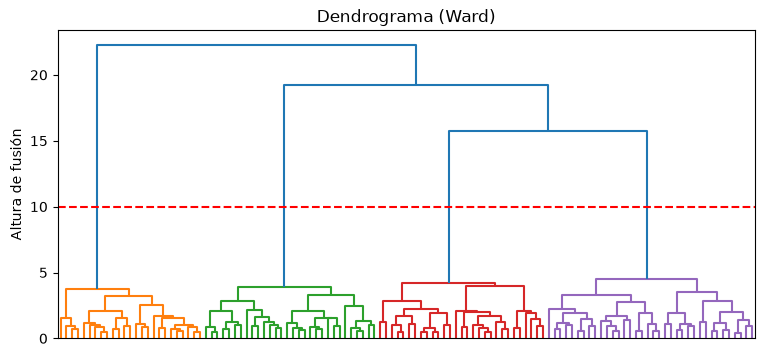

In [4]:
enlace = linkage(Z, method="ward")          # distancia euclidiana + Ward
alturas = enlace[-8:, 2][::-1]
print(pd.Series(alturas.round(2), index=[f"{k + 1} -> {k}" for k in range(1, 9)]))

plt.figure(figsize=(9, 4))
dendrogram(enlace, no_labels=True, color_threshold=10)
plt.axhline(10, ls="--", color="red"); plt.ylabel("Altura de fusión"); plt.title("Dendrograma (Ward)")
plt.show()

**¿Qué observar?** Las fusiones de 8 a 4 grupos ocurren a alturas parecidas (3,9 a 4,5) y la de 4 a 3 salta a 15,8 (15,7 en R). Ese salto sugiere **cuatro grupos**. Recuerda que en Ward la altura reportada es $\sqrt{2\Delta}$, no el aumento $\Delta$ de la suma de cuadrados.

In [5]:
for k in range(2, 7):
    g = fcluster(enlace, t=k, criterion="maxclust")
    print(f"k = {k}: silueta = {silhouette_score(Z, g):.3f}")

k = 2: silueta = 0.370
k = 3: silueta = 0.428
k = 4: silueta = 0.497
k = 5: silueta = 0.388
k = 6: silueta = 0.322


**¿Qué observar?** La silueta máxima es 0,497 con k = 4. Según Kaufman y Rousseeuw (1990), está en el límite entre estructura **débil** (0,26–0,50) y **razonable** (0,51–0,70): hay grupos, pero con zonas de contacto.

## 3. K-means

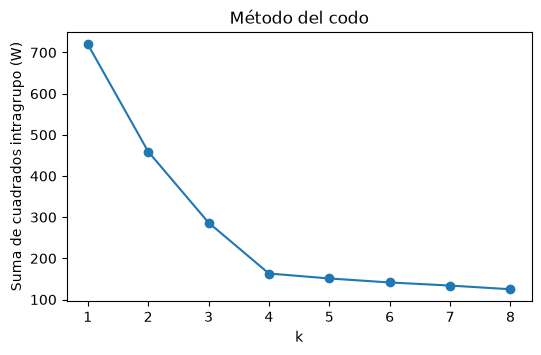

R² (variabilidad entre grupos / total): 0.773


k-means,0,1,2,3
Ward,,,,
1,0,0,25,0
2,0,30,0,0
3,0,0,0,29
4,36,0,0,0


In [6]:
inercias = [KMeans(n_clusters=k, n_init=25, random_state=2026).fit(Z).inertia_ for k in range(1, 9)]
plt.figure(figsize=(6, 3.5)); plt.plot(range(1, 9), inercias, marker="o")
plt.xlabel("k"); plt.ylabel("Suma de cuadrados intragrupo (W)"); plt.title("Método del codo"); plt.show()

km = KMeans(n_clusters=4, n_init=25, random_state=2026).fit(Z)   # 25 arranques, semilla fija
sc_total = ((Z - Z.mean(axis=0))**2).sum()
print("R² (variabilidad entre grupos / total):", round(1 - km.inertia_ / sc_total, 3))
grupos_hc = fcluster(enlace, t=4, criterion="maxclust")
pd.crosstab(grupos_hc, km.labels_, rownames=["Ward"], colnames=["k-means"])

**¿Qué observar?** El codo está en k = 4, con R² = 0,773. La tabla cruzada muestra que Ward y k-means producen la **misma partición** (las etiquetas de los grupos son arbitrarias). Es una evidencia limitada, porque ambos minimizan la suma de cuadrados intragrupo; por eso conviene revisar la estabilidad.

## 4. Estabilidad de la segmentación

In [7]:
base = km.labels_
# (a) Un solo arranque aleatorio con 20 semillas distintas
ari_1 = [adjusted_rand_score(base, KMeans(4, n_init=1, random_state=s).fit_predict(Z)) for s in range(20)]
# (b) 50 submuestras del 80 % con 25 arranques
rng = np.random.default_rng(1)
ari_sub = []
for b in range(50):
    idx = rng.choice(len(Z), int(0.8 * len(Z)), replace=False)
    etiquetas = KMeans(4, n_init=25, random_state=b).fit_predict(Z[idx])
    ari_sub.append(adjusted_rand_score(base[idx], etiquetas))
print(f"Un arranque: ARI medio = {np.mean(ari_1):.3f}, mínimo = {np.min(ari_1):.3f}")
print(f"Submuestras: ARI medio = {np.mean(ari_sub):.3f}, mínimo = {np.min(ari_sub):.3f}")

Un arranque: ARI medio = 0.958, mínimo = 0.580
Submuestras: ARI medio = 0.997, mínimo = 0.969


**¿Qué observar?** El índice de Rand ajustado (ARI) vale 1 cuando dos particiones coinciden. En submuestras del 80 % la solución es muy estable (ARI medio 0,997); con un solo arranque, en cambio, el ARI llega a bajar a 0,58: k-means puede quedar atrapado en un óptimo local. **Usa siempre varios arranques y fija la semilla.**

## 5. Caracterización de los grupos

In [8]:
clientes["grupo"] = km.labels_
perfiles = clientes.groupby("grupo")[list(variables)].mean()

def nombre(fila):
    if fila["recencia_dias"] > 90: return "En riesgo de abandono"
    if fila["antiguedad_meses"] < 12: return "Nuevos exploradores"
    if fila["frecuencia_anual"] > 18: return "Frecuentes de alto valor"
    return "Ocasionales de ticket alto"

perfiles["nombre"] = perfiles.apply(nombre, axis=1)
perfiles["n"] = clientes["grupo"].value_counts().sort_index()
perfiles.round(1)

,recencia_dias,frecuencia_anual,ticket_promedio,antiguedad_meses,visitas_mes,devoluciones_pct,nombre,n
grupo,,,,,,,,
0,12.8,23.9,191.2,38.6,13.3,3.1,Frecuentes de alto valor,36
1,13.1,10.0,76.1,7.0,15.8,7.1,Nuevos exploradores,30
2,119.2,4.9,95.6,29.7,3.2,12.9,En riesgo de abandono,25
3,57.2,6.4,245.4,29.2,5.3,4.5,Ocasionales de ticket alto,29


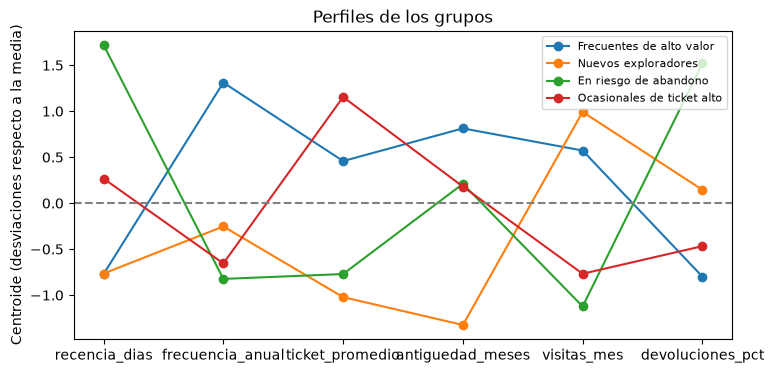

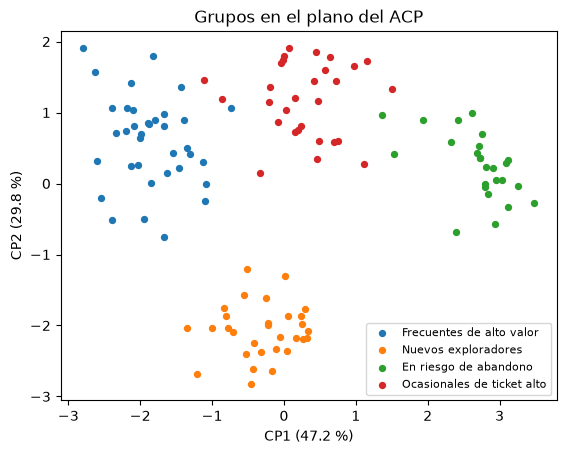

In [9]:
centroides = pd.DataFrame(km.cluster_centers_, columns=variables, index=perfiles["nombre"])
centroides.T.plot(marker="o", figsize=(8.5, 4))
plt.axhline(0, ls="--", color="gray"); plt.ylabel("Centroide (desviaciones respecto a la media)")
plt.title("Perfiles de los grupos"); plt.legend(fontsize=8); plt.show()

pca = PCA(2).fit(Z); P2 = pca.transform(Z)
for g_, nm in perfiles["nombre"].items():
    m = km.labels_ == g_
    plt.scatter(P2[m, 0], P2[m, 1], s=18, label=nm)
plt.xlabel(f"CP1 ({100 * pca.explained_variance_ratio_[0]:.1f} %)"); plt.ylabel(f"CP2 ({100 * pca.explained_variance_ratio_[1]:.1f} %)")
plt.legend(fontsize=8); plt.title("Grupos en el plano del ACP"); plt.show()

**¿Qué observar?** Cuatro perfiles: *Frecuentes de alto valor*, *Ocasionales de ticket alto*, *Nuevos exploradores* y *En riesgo de abandono*. Cada nombre resume una combinación de variables. Los dos primeros componentes del ACP (Unidad 1) recogen el 77,1 % de la varianza y en ese plano los grupos aparecen separados.

> **Integración:** al cruzar los grupos con el estado observado seis meses después (sin usarlo para formarlos), 24 de los 25 clientes «En riesgo de abandono» se retiraron. Ejecuta `pd.crosstab(perfiles["nombre"].reindex(clientes["grupo"]).values, clientes["estado_6m"])` para comprobarlo.

In [10]:
pd.crosstab(perfiles["nombre"].reindex(clientes["grupo"]).values, clientes["estado_6m"])

estado_6m,Activo,Inactivo,Retirado
row_0,,,
En riesgo de abandono,0,1,24
Frecuentes de alto valor,36,0,0
Nuevos exploradores,6,18,6
Ocasionales de ticket alto,10,11,8


### ✍️ Tu turno

Calcula la silueta promedio de **k-means** (no de Ward) para k = 2, …, 6. ¿Coincide el valor de k con el de la solución jerárquica?

*Pista:* usa `silhouette_score(Z, KMeans(k, n_init=25, random_state=2026).fit_predict(Z))`.

<details>
<summary><b>Ver una solución posible</b></summary>

```python
for k in range(2, 7):
    print(k, round(silhouette_score(Z, KMeans(k, n_init=25, random_state=2026).fit_predict(Z)), 3))
```

Siluetas de k-means: k = 2: 0,343; k = 3: 0,421; k = 4: 0,497; k = 5: 0,400; k = 6: 0,333. El máximo está en k = 4, igual que con Ward, y también en el límite entre estructura débil y razonable.

</details>

---
### Conecta con tu proyecto

Repite este flujo con la base de tu equipo. Guarda el cuaderno con salidas y verifica que se ejecute de principio a fin (*Entorno de ejecución → Reiniciar y ejecutar todo*) antes de entregarlo.

**Siguiente cuaderno:** `03b_analisis_discriminante.ipynb`